In [47]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent))

from src.black_scholes import black_scholes_price
from src.monte_carlo import monte_carlo_european

## Simulating Terminal Stock Prices

To price an option using Monte Carlo simulation, we first need to generate possible stock prices at the option's expiry.

Under the Black-Scholes framework, the stock price is assumed to follow **Geometric Brownian Motion (GBM)**. The terminal stock price can be simulated directly using:

$$
S_T = S_0 \exp\left[
\left(r-\frac{1}{2}\sigma^2\right)T
+
\sigma\sqrt{T}Z
\right]
$$

where:

- $S_0$ is the current stock price
- $S_T$ is the simulated stock price at expiry
- $r$ is the risk-free interest rate
- $\sigma$ is the volatility of the stock
- $T$ is the time to expiry
- $Z \sim N(0,1)$ is a random draw from the standard normal distribution

The expression inside the exponential can be separated into two components:

$$
\underbrace{\left(r-\frac{1}{2}\sigma^2\right)T}_{\text{drift}}
+
\underbrace{\sigma\sqrt{T}Z}_{\text{random component}}
$$

The **drift** represents the deterministic component of the stock's evolution under the risk-neutral measure, while the **random component** introduces uncertainty into each simulated outcome.

By repeatedly drawing different values of $Z$, we generate a distribution of possible terminal stock prices:

$$
S_T^{(1)}, S_T^{(2)}, \ldots, S_T^{(M)}
$$

where $M$ is the total number of Monte Carlo simulations.

In [48]:
np.random.seed(42)

M = 100000
Z = np.random.standard_normal(M)

print(Z[:10])
print("Mean:", np.mean(Z))
print("Standard deviation:", np.std(Z))

[ 0.49671415 -0.1382643   0.64768854  1.52302986 -0.23415337 -0.23413696
  1.57921282  0.76743473 -0.46947439  0.54256004]
Mean: 0.0009668681409495966
Standard deviation: 1.0009009542948903


In [49]:
S0 = 100       # Initial stock price
K = 100        # Strike price
T = 1.0        # Time to maturity (years)
r = 0.05       # Risk-free rate
sigma = 0.20   # Volatility


In [50]:
drift = (r - 0.5 * sigma**2) * T
diffusion = sigma * np.sqrt(T) * Z

ST = S0 * np.exp(drift + diffusion)

In [51]:
ST

array([113.8080226 , 100.23498965, 117.29684912, ..., 111.83305754,
        98.78560066, 105.54978889], shape=(100000,))

In [52]:
simulated_mean = np.mean(ST)
theoretical_mean = S0 * np.exp(r * T)

In [53]:
call_payoffs = np.maximum(ST - K, 0)

In [54]:
mc_call_price = np.exp(-r*T) * np.mean(call_payoffs)

In [55]:
print("Monte Carlo Call Price:", mc_call_price)

Monte Carlo Call Price: 10.47389196070258


In [56]:
standard_error = np.exp(-r*T) * (np.std(call_payoffs)/np.sqrt(M))

In [57]:
standard_error

np.float64(0.046589073899027174)

In [58]:
lower_bound = mc_call_price - 1.96 * standard_error
upper_bound = mc_call_price + 1.96 * standard_error

In [59]:
lower_bound

np.float64(10.382577375860487)

In [60]:
upper_bound

np.float64(10.565206545544674)

In [61]:
M_values = [100, 1000, 10000, 100000, 1000000]

In [62]:
mc_prices = []

In [63]:
np.random.seed(42)

M_values = [100, 1000, 10000, 100000, 1000000]
mc_prices = []

for M in M_values:
    Z = np.random.standard_normal(M)
    diffusion = sigma * np.sqrt(T) * Z

    ST = S0 * np.exp(drift + diffusion)
    call_payoffs = np.maximum(ST - K, 0)
    price = np.exp(-r*T) * np.mean(call_payoffs)

    mc_prices.append(price)

In [64]:
bs_price = black_scholes_price(
    S0, K, T, r, 0.0, sigma, "call"
)

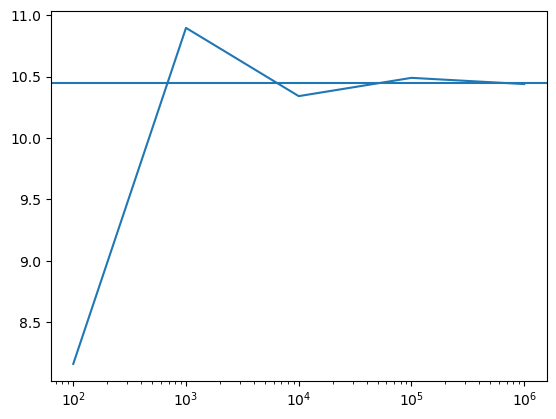

In [65]:
plt.plot(M_values, mc_prices)
plt.axhline(bs_price)
plt.xscale("log")

## Reusable Monte Carlo Pricer

The manual simulation above demonstrates the pricing procedure explicitly. The reusable implementation in `src.monte_carlo` provides the same pricing framework with a fixed random seed for reproducible numerical results.

In [66]:
mc_call = monte_carlo_european(
    S0, K, T, r, sigma,
    M=100_000,
    option_type="call",
    seed=42,
)

mc_put = monte_carlo_european(
    S0, K, T, r, sigma,
    M=100_000,
    option_type="put",
    seed=42,
)

print("Monte Carlo Call:", mc_call)
print("Monte Carlo Put:", mc_put)

Monte Carlo Call: 10.420541193153111
Monte Carlo Put: 5.612203851328205
